# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [195]:
# Proponowane importy — możesz je zmienić lub rozszerzyć.
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [196]:
# Pobranie niezmienionego archiwum z oficjalnymi podziałami train/test.
DATA_DIR = Path("data/zadanie-1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")

print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")

Dane zapisano w: data/zadanie-1/pendigits


## A — Poznanie i przygotowanie danych

Rozpoznaj zmienną docelową i cechy, sprawdź rozkład klas, braki, duplikaty oraz zakresy wartości. Pokaż krótką eksplorację danych i uzasadnij preprocessing. Zachowaj oficjalny podział danych; nie zastępuj go losowym podziałem.

In [197]:
tes_path = Path.cwd() / Path("data/zadanie-1/pendigits") / "pendigits.tes"
tra_path = Path.cwd() / Path("data/zadanie-1/pendigits") / "pendigits.tra"
df_tes = pd.read_csv(tes_path, header=None)
df_tra = pd.read_csv(tra_path, header=None)
#pobranie danych do pd.DataFrame

In [198]:
print(df_tes.head())
print(max(df_tes.max()), min(df_tes.min()), max(df_tra.max()), min(df_tra.min()))
print(df_tes.shape, df_tra.shape)
#kształt (n, 17), siedemnastym atrybutem jest klasa 0-9, a 16 pierwszych oznacza współżędne (x, y) dla 8 punktów
#powstałych przez normalizację oryginalnych pomiarów. Punkty przeskalowane przez 1/5, ponieważ oryginalny
#zakres współżednych to 0-500, a w danych znormalizowanych - 0-100

   0    1   2    3   4   5    6   7    8   9    10  11   12   13   14   15  16
0  88   92   2   99  16  66   94  37   70   0    0  24   42   65  100  100   8
1  80  100  18   98  60  66  100  29   42   0    0  23   42   61   56   98   8
2   0   94   9   57  20  19    7   0   20  36   70  68  100  100   18   92   8
3  95   82  71  100  27  77   77  73  100  80   93  42   56   13    0    0   9
4  68  100   6   88  47  75   87  82   85  56  100  29   75    6    0    0   9
100 0 100 0
(3498, 17) (7494, 17)


In [199]:
X_tes, y_tes = df_tes.iloc[:,:16], df_tes.iloc[:,16]
X_tra, y_tra = df_tra.iloc[:,:16], df_tra.iloc[:,16]

In [200]:
print(y_tes.value_counts())
print(y_tra.value_counts())
#równomierny rozkład klas - 335-364 próbek dla każdej klasy w test i 719-780 dla tra

16
1    364
4    364
7    364
2    364
0    363
8    336
9    336
3    336
6    336
5    335
Name: count, dtype: int64
16
2    780
4    780
0    780
1    779
7    778
6    720
5    720
8    719
9    719
3    719
Name: count, dtype: int64


In [201]:
print(df_tes.isnull().sum(axis=1).sum(axis=0))
print(df_tra.isnull().sum(axis=1).sum(axis=0))
#nie ma braków

0
0


In [202]:
print(df_tes.duplicated().sum(axis=0))
print(df_tra.duplicated().sum(axis=0))
#nie ma duplikatów

0
0


In [203]:
#preprocessing nie jest potrzeny, ponieważ: nie ma duplikatów, nie ma brakujących wartości,
#każdy atrybut jest w zakresie 0-100 - eliminuje to potrzebę skalowania, klasy są reprezentowane
#jako wartości liczbowe 0-9. Mimo jednakowej skali dla atrbutów, użyję StandardScaler, ponieważ
#niektóre algorytm dokonują szybszej optymalizacji z danymi skupionymi wokół 0.
#najpier użyte jest fit_transform(), żeby obliczyć parametry tranformacji(średnia, odchylenie) na podstawe
#danych treningowych, a dane testowe muszą skalowane zgodnie z tymi parametrami, żeby dane testowe były,
#w takiej samej skali co treningowe. Dlatego na danych testowych użyte jest samo transform()

## B — Modelowanie

Zbuduj prosty model bazowy i porównaj go z kilkoma klasyfikatorami statystycznymi lub klasycznego uczenia maszynowego. Wykonaj dobór modeli, strojenie i sposób zapobiegania wyciekowi danych. 

In [204]:
#tablica na wyniki wydajności modeli
model_results = []
results_columns = ["model", "accuracy", "f1", "fit_time", "score_time", "val_accuracy"]

In [205]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

#model bazowy losując klasę na podstawie rozkładu klas (stratified)
dummy = DummyClassifier(strategy='stratified')
cv_dummy = cross_validate(dummy, X_tra, y_tra, scoring="accuracy")
dummy_fit_time = cv_dummy["fit_time"].mean()
dummy_score_time = cv_dummy["score_time"].mean()
dummy_test_score = cv_dummy["test_score"].mean()
dummy.fit(X_tra, y_tra)
y_preds_dummy = dummy.predict(X_tes)
dummy_accuracy = accuracy_score(y_tes, y_preds_dummy)
dummy_f1 = f1_score(y_tes, y_preds_dummy, average="macro")
model_results.append(["dummy", dummy_accuracy, dummy_f1, dummy_fit_time, dummy_score_time, dummy_test_score])

In [206]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn import svm
from sklearn.model_selection import GridSearchCV

In [207]:
input_ovr = [("scaler", StandardScaler()), ("ovr_cf", OneVsRestClassifier(LogisticRegression()))]
pipe_ovr = Pipeline(input_ovr)
cv_ovr = cross_validate(pipe_ovr, X_tra, y_tra, scoring="accuracy")
ovr_fit_time = cv_ovr["fit_time"].mean()
ovr_score_time = cv_ovr["score_time"].mean()
ovr_test_score = cv_ovr["test_score"].mean()
pipe_ovr.fit(X_tra, y_tra)
y_preds_ovr = pipe_ovr.predict(X_tes)
ovr_accuracy = accuracy_score(y_tes, y_preds_ovr)
ovr_f1 = f1_score(y_tes, y_preds_ovr, average="macro")
model_results.append(["logistic_regression_ovr", ovr_accuracy, ovr_f1, ovr_fit_time, ovr_score_time, ovr_test_score])

In [208]:
input_ovo = [("scaler", StandardScaler()), ("ovo_cf", OneVsOneClassifier(LogisticRegression()))]
pipe_ovo = Pipeline(input_ovo)
cv_ovo = cross_validate(pipe_ovo, X_tra, y_tra, scoring="accuracy")
ovo_fit_time = cv_ovo["fit_time"].mean()
ovo_score_time = cv_ovo["score_time"].mean()
ovo_test_score = cv_ovo["test_score"].mean()
pipe_ovo.fit(X_tra, y_tra)
y_preds_ovo = pipe_ovo.predict(X_tes)
ovo_accuracy = accuracy_score(y_tes, y_preds_ovo)
ovo_f1 = f1_score(y_tes, y_preds_ovo, average="macro")
model_results.append(["logistic_regression_ovo", ovo_accuracy, ovo_f1, ovo_fit_time, ovo_score_time, ovo_test_score])

In [209]:
input_svc = [("scaler", StandardScaler()), ("svc", svm.SVC(C=10, kernel="rbf"))]
pipe_svc = Pipeline(input_svc)
cv_svc = cross_validate(pipe_svc, X_tra, y_tra, scoring="accuracy")
svc_fit_time = cv_svc["fit_time"].mean()
svc_score_time = cv_svc["score_time"].mean()
svc_test_score = cv_svc["test_score"].mean()
pipe_svc.fit(X_tra, y_tra)
y_preds_svc = pipe_svc.predict(X_tes)
svc_accuracy = accuracy_score(y_tes, y_preds_svc)
svc_f1 = f1_score(y_tes, y_preds_svc, average="macro")
model_results.append(["svc", svc_accuracy, svc_f1, svc_fit_time, svc_score_time, svc_test_score])

In [210]:
from timeit import time
input_svc_grid = [("scaler", StandardScaler()), ("svc", svm.SVC())]
pipe_svc_grid = Pipeline(input_svc_grid)
params_svc = [{"svc__C": [0.1, 1, 10, 100], "svc__kernel": ["linear"]}, 
              {"svc__C": [0.1, 1, 10, 100], "svc__kernel": ["rbf"], "svc__gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1]}]
grid_svc = GridSearchCV(pipe_svc_grid, params_svc, cv=4, scoring="accuracy")
start_time = time.time()
grid_svc.fit(X_tra, y_tra)
end_time = time.time()
best_svc = grid_svc.best_estimator_
#best_svc.fit(X_tra, y_tra) nie potrzebne ponieważ najlepszy estymator jest już wytrenowany przez GridSearchCV (refit=True)
y_preds_svc_grid = best_svc.predict(X_tes)
svc_grid_accuracy = accuracy_score(y_tes, y_preds_svc_grid)
svc_grid_f1 = f1_score(y_tes, y_preds_svc_grid, average="macro")
best_index = grid_svc.best_index_
#cross validation zostało już przeprowadzone w GridSearchCV, więc nie ma potrzeby ponownie wykonywać CV.
svc_grid_fit_time = grid_svc.cv_results_['mean_fit_time'][best_index]
svc_grid_score_time = grid_svc.cv_results_['mean_score_time'][best_index]
svc_grid_test_score = grid_svc.cv_results_['mean_test_score'][best_index]
time_of_grid_search = end_time - start_time
model_results.append(["svc_grid_search", svc_grid_accuracy, svc_grid_f1, svc_grid_fit_time, svc_grid_score_time, svc_grid_test_score])

In [211]:
from sklearn.tree import DecisionTreeClassifier
tree_cf = DecisionTreeClassifier(criterion="entropy", max_depth=12)
cv_tree = cross_validate(tree_cf, X_tra, y_tra, scoring="accuracy")
tree_fit_time = cv_tree["fit_time"].mean()
tree_score_time = cv_tree["score_time"].mean()
tree_test_score = cv_tree["test_score"].mean()
tree_cf.fit(X_tra, y_tra)
y_preds_tree = tree_cf.predict(X_tes)
tree_accuracy = accuracy_score(y_tes, y_preds_tree)
tree_f1 = f1_score(y_tes, y_preds_tree, average="macro")
model_results.append(["tree", tree_accuracy, tree_f1, tree_fit_time, tree_score_time, tree_test_score])

In [212]:
!uv pip install xgboost
#pakiet xgboost być pobrany
from xgboost import XGBClassifier

xgb_clf = XGBClassifier()
cv_xgb = cross_validate(xgb_clf, X_tra, y_tra, scoring="accuracy")
xgb_fit_time = cv_xgb["fit_time"].mean()
xgb_score_time = cv_xgb["score_time"].mean()
xgb_test_score = cv_xgb["test_score"].mean()
xgb_clf.fit(X_tra, y_tra)
y_pred_xgb = xgb_clf.predict(X_tes)
xgb_accuracy = accuracy_score(y_tes, y_pred_xgb)
xgb_f1 = f1_score(y_tes, y_pred_xgb, average="macro")
model_results.append(["xgb", xgb_accuracy, xgb_f1, xgb_fit_time, xgb_score_time, xgb_test_score])

Using Python 3.13.16 environment at: /home/igorszyszkowski/Rekrutacja-AI-Med-2026-2027/.venv
Checked 1 package in 3ms


In [213]:
#pipeline zapobiega wyciekowi danych. Tylko na danych treningowych wykonywany jest fit_transform w pipe, 
#a pipe.predict na danych testowych nie wykonuje transform.

## C — Porównanie i wnioski

Porównaj modele na oficjalnym zbiorze testowym za pomocą odpowiednich metryk liczbowych. Uwzględnij błędy oraz praktyczny koszt modeli, np. czas uczenia i inferencji albo liczbę parametrów. Odpowiedz, czy wzrost złożoności jest wart uzyskanej poprawy.

In [214]:
df_results = pd.DataFrame(model_results, columns=results_columns)
df_results.sort_values(by="accuracy", inplace=True, ascending=False)
df_results.reset_index(drop=True, inplace=True)
print(df_results)
print(f"best model by accuracy: {df_results.loc[0, "model"]}")
#model svc nie tylko osiąga najlepszą skuteczność, ale również ma jeden z najlepszych czasów fit_time
#svc mimo dobierania parametrów przez GridSearch radzi sobie minimalnie gorzej. Koszt czasowy GridSearch
#jest bardzo wysoki (time_of_grid_search ~= 45s), dlatego użycie GridSearch w tym przypadku nie przynosi żadnych efektów.

                     model  accuracy        f1  fit_time  score_time  \
0                      svc  0.981418  0.981353  0.086898    0.041005   
1          svc_grid_search  0.980560  0.980499  0.105906    0.058507   
2                      xgb  0.964265  0.964534  1.031354    0.008605   
3  logistic_regression_ovo  0.949971  0.950199  0.189278    0.018470   
4                     tree  0.917381  0.917175  0.034259    0.002236   
5  logistic_regression_ovr  0.895369  0.896176  0.121088    0.004096   
6                    dummy  0.103488  0.103331  0.001642    0.001640   

   val_accuracy  
0      0.996397  
1      0.996798  
2      0.989725  
3      0.980652  
4      0.962369  
5      0.945024  
6      0.101284  
best model by accuracy: svc


In [215]:
#classification_report dla najlepszego modelu
print(classification_report(y_tes, y_preds_svc))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99       363
           1       0.97      0.99      0.98       364
           2       0.99      1.00      0.99       364
           3       0.97      0.99      0.98       336
           4       1.00      0.99      0.99       364
           5       0.98      0.99      0.98       335
           6       0.99      1.00      1.00       336
           7       0.99      0.92      0.95       364
           8       0.97      1.00      0.98       336
           9       0.96      0.98      0.97       336

    accuracy                           0.98      3498
   macro avg       0.98      0.98      0.98      3498
weighted avg       0.98      0.98      0.98      3498



In [216]:
#Confusion matrix dla najlepszego modelu
cm = confusion_matrix(y_tes, y_preds_svc)
print(cm)

[[354   0   0   0   0   0   1   0   8   0]
 [  0 359   2   0   1   0   0   2   0   0]
 [  0   0 364   0   0   0   0   0   0   0]
 [  0   1   0 333   0   0   0   0   0   2]
 [  0   0   0   0 359   4   1   0   0   0]
 [  0   0   0   3   0 330   0   0   1   1]
 [  1   0   0   0   0   0 335   0   0   0]
 [  0   8   2   8   0   0   0 336   1   9]
 [  0   0   0   0   0   1   0   0 335   0]
 [  0   1   0   1   0   2   0   3   1 328]]


Text(0, 0.5, 'number')

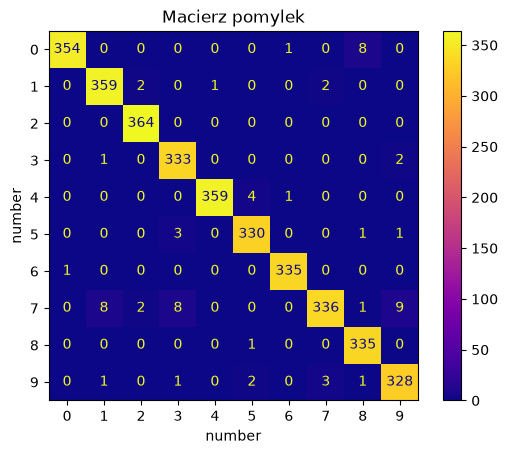

In [217]:
#wizualizacja confusionMatrix
cm_plt = ConfusionMatrixDisplay(confusion_matrix=cm)
cm_plt.plot(cmap=plt.cm.plasma)
plt.title("Macierz pomylek")
plt.xlabel("number")
plt.ylabel("number")

real_number: 0, predicted_number: 0


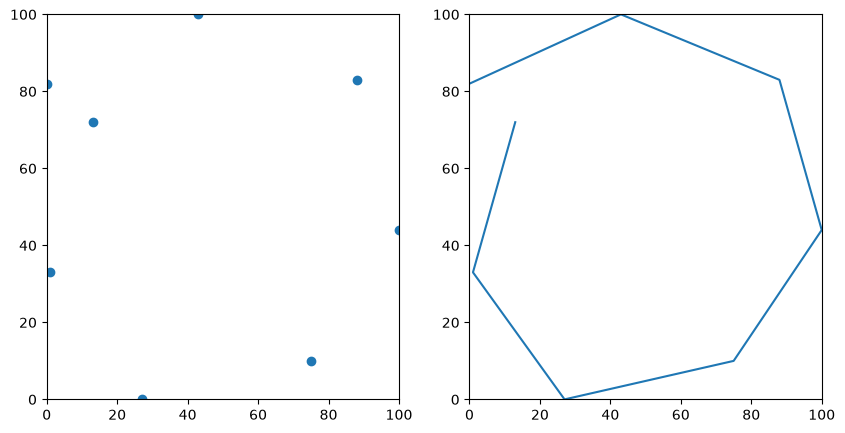

In [218]:
#na koniec wizualizacja danych testowych i sprawdzenie predykcji najlepszego modelu
best_model = pipe_svc
sample_tes = df_tes.sample(1)
real_number = sample_tes.iloc[0, 16]
predicted_number = best_model.predict(sample_tes.iloc[0:1,:16])[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.scatter([sample_tes[i] for i in range(0, 16, 2)], [sample_tes[i + 1] for i in range(0, 16, 2)])
ax1.set_ylim(0, 100)
ax1.set_xlim(0, 100)
ax2.plot([sample_tes[i] for i in range(0, 16, 2)], [sample_tes[i + 1] for i in range(0, 16, 2)])
ax2.set_ylim(0, 100)
ax2.set_xlim(0, 100)
print(f"real_number: {real_number}, predicted_number: {predicted_number}")

## Oddanie zadania

Zapisz kod, wyniki, wykresy i krótkie uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i upewnij się, że notatnik można uruchomić od początku do końca. Wykonaj commit po zakończeniu zadania aby znalazł się na repozytorium.

użyte źródła to głównie dokumentacja sklearn (https://scikit-learn.org/stable/), używana do sprawdzenia składni i parametrów algorytmów ML, klas i funkcji, dokumentacja pandas (https://pandas.pydata.org/docs), gemini użyty do lepszego zrozumienia algorytmów, ich parametrów, metryk, oraz szukania potrzebnych mi metod (np GridSearchCV.cv_results_)